#Imports


In [170]:
import glob
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
)
from sklearn.model_selection import (
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from xgboost import XGBClassifier

# Download e Carregamento do DATASET

In [171]:
# Download latest version
path = kagglehub.dataset_download("amitvkulkarni/lifestyle-factors-influencing-osteoporosis")
caminho_completo = glob.glob(f"{path}/*.csv")[0]

print("Path to dataset files:", path)
print("Path to dataset files:", caminho_completo)

Using Colab cache for faster access to the 'lifestyle-factors-influencing-osteoporosis' dataset.
Path to dataset files: /kaggle/input/lifestyle-factors-influencing-osteoporosis
Path to dataset files: /kaggle/input/lifestyle-factors-influencing-osteoporosis/osteoporosis.csv


In [172]:
df = pd.read_csv(caminho_completo)

In [173]:
display(df)

,Id,Age,Gender,Hormonal Changes,Family History,Race/Ethnicity,Body Weight,Calcium Intake,Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Medical Conditions,Medications,Prior Fractures,Osteoporosis
0,1734616,69,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,Corticosteroids,Yes,1
1,1419098,32,Female,Normal,Yes,Asian,Underweight,Low,Sufficient,Sedentary,No,NaN,NaN,NaN,Yes,1
2,1797916,89,Female,Postmenopausal,No,Caucasian,Normal,Adequate,Sufficient,Active,No,Moderate,Hyperthyroidism,Corticosteroids,No,1
3,1805337,78,Female,Normal,No,Caucasian,Underweight,Adequate,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,No,1
4,1351334,38,Male,Postmenopausal,Yes,African American,Normal,Low,Sufficient,Active,Yes,NaN,Rheumatoid Arthritis,NaN,Yes,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1953,1991635,19,Female,Normal,Yes,African American,Normal,Adequate,Sufficient,Sedentary,Yes,Moderate,Rheumatoid Arthritis,NaN,Yes,0
1954,1528601,23,Female,Postmenopausal,Yes,Caucasian,Underweight,Low,Insufficient,Active,No,NaN,NaN,Corticosteroids,No,0
1955,1990957,34,Female,Postmenopausal,No,African American,Underweight,Low,Sufficient,Sedentary,No,NaN,Hyperthyroidism,NaN,No,0
1956,1779848,25,Male,Postmenopausal,No,African American,Normal,Low,Insufficient,Sedentary,Yes,NaN,Rheumatoid Arthritis,Corticosteroids,Yes,0


In [174]:
df.columns

Index(['Id', 'Age', 'Gender', 'Hormonal Changes', 'Family History',
       'Race/Ethnicity', 'Body Weight', 'Calcium Intake', 'Vitamin D Intake',
       'Physical Activity', 'Smoking', 'Alcohol Consumption',
       'Medical Conditions', 'Medications', 'Prior Fractures', 'Osteoporosis'],
      dtype='object')

# Tratamento Dataset


##Deletando a coluna ID

In [175]:
df = df.drop(columns=['Id'])

## Tratamento da Coluna Gender (Gênero)

In [176]:
# Valores unicos coluna Gender
df['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [177]:
df['Gender'] = df['Gender'].replace({'Female': 1, 'Male': 0})

/tmp/ipykernel_2287/693543352.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Gender'] = df['Gender'].replace({'Female': 1, 'Male': 0})


In [178]:
# Conferindo modificações
df['Gender'].unique()

array([1, 0])

## Tratamento da Coluna Hormonal Changes (Alterações Hormonais)

In [179]:
# Valores unicos coluna Hormonal Changes
df['Hormonal Changes'].unique()

array(['Normal', 'Postmenopausal'], dtype=object)

In [180]:
df['Hormonal Changes'] = df['Hormonal Changes'].replace({'Postmenopausal': 1, 'Normal': 0})

/tmp/ipykernel_2287/3827753601.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Hormonal Changes'] = df['Hormonal Changes'].replace({'Postmenopausal': 1, 'Normal': 0})


In [181]:
# Conferindo modificações
df['Hormonal Changes'].unique()

array([0, 1])

## Tratamento da Coluna Family History (Histórico Familiar)

In [182]:
# Valores unicos coluna Family History
df['Family History'].unique()

array(['Yes', 'No'], dtype=object)

In [183]:
df['Family History'] = df['Family History'].replace({'Yes': 1, 'No': 0})

/tmp/ipykernel_2287/1976639463.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Family History'] = df['Family History'].replace({'Yes': 1, 'No': 0})


In [184]:
df['Family History'].unique()

array([1, 0])

## Tratamento da Coluna Race/Ethnicity (Raça/Etnia)

In [185]:
# Valores unicos coluna Race/Ethnicity
df['Race/Ethnicity'].unique()

array(['Asian', 'Caucasian', 'African American'], dtype=object)

In [186]:
df = pd.get_dummies(df, columns=['Race/Ethnicity'], dtype=int)

In [187]:
df.columns = df.columns.str.replace('Race/Ethnicity_', '', regex=False)

## Tratamento da Coluna Body Weight (Peso Corporal)

In [188]:
# Valores unicos coluna Body Weight
df['Body Weight'].unique()

array(['Underweight', 'Normal'], dtype=object)

In [189]:
df['Body Weight'] = df['Body Weight'].replace({'Underweight': 1, 'Normal': 0})

/tmp/ipykernel_2287/1620137891.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Body Weight'] = df['Body Weight'].replace({'Underweight': 1, 'Normal': 0})


In [190]:
df['Body Weight'].unique()

array([1, 0])

renomeando a coluna para Underweight(abaixo do peso) pois a coluna so lista quem esta com o peso normal ou abaixo do peso

In [191]:
df = df.rename(columns={'Body Weight': 'Underweight'})

## Tratamento da Coluna Calcium Intake (Ingestão de Cálcio)

In [192]:
# Valores unicos coluna Calcium Intake
df['Calcium Intake'].unique()

array(['Low', 'Adequate'], dtype=object)

In [193]:
df['Calcium Intake'] = df['Calcium Intake'].replace({'Low': 1, 'Adequate': 0})

/tmp/ipykernel_2287/371560926.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Calcium Intake'] = df['Calcium Intake'].replace({'Low': 1, 'Adequate': 0})


In [194]:
df['Calcium Intake'].unique()

array([1, 0])

renomeando a coluna para Low Calcium Intake(baixa ingestão de calcio) pois a coluna so lista quem ingere calcio normal ou pouco

In [195]:
df = df.rename(columns={'Calcium Intake': 'Low Calcium Intake'})

## Tratamento da Coluna Vitamin D Intake (Ingestão de Vitamina D)

In [196]:
# Valores unicos coluna Vitamin D Intake
df['Vitamin D Intake'].unique()

array(['Sufficient', 'Insufficient'], dtype=object)

In [197]:
df['Vitamin D Intake'] = df['Vitamin D Intake'].replace({'Insufficient': 1, 'Sufficient': 0})

/tmp/ipykernel_2287/1594893433.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Vitamin D Intake'] = df['Vitamin D Intake'].replace({'Insufficient': 1, 'Sufficient': 0})


In [198]:
df['Vitamin D Intake'].unique()

array([0, 1])

renomeando a coluna para Low Vitamin D Intake(baixa ingestão de vitamina D) pois a coluna so lista quem ingere vitamina D suficiente ou insuficiente

In [199]:
df = df.rename(columns={'Vitamin D Intake': 'Low Vitamin D Intake'})

## Tratamento da Coluna Physical Activity (Atividade Física)

In [200]:
# Valores unicos coluna Physical Activity
df['Physical Activity'].unique()

array(['Sedentary', 'Active'], dtype=object)

In [201]:
df['Physical Activity'] = df['Physical Activity'].replace({'Active': 1, 'Sedentary': 0})

/tmp/ipykernel_2287/2347283158.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Physical Activity'] = df['Physical Activity'].replace({'Active': 1, 'Sedentary': 0})


In [202]:
df['Physical Activity'].unique()

array([0, 1])

## Tratamento da Coluna Smoking (Tabagismo)

In [203]:
# Valores unicos coluna Smoking
df['Smoking'].unique()

array(['Yes', 'No'], dtype=object)

In [204]:
df['Smoking'] = df['Smoking'].replace({'Yes': 1, 'No': 0})

/tmp/ipykernel_2287/3447936352.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Smoking'] = df['Smoking'].replace({'Yes': 1, 'No': 0})


In [205]:
df['Smoking'].unique()

array([1, 0])

## Tratamento da Coluna Alcohol Consumption (Consumo de Álcool)

In [206]:
# Valores unicos coluna Alcohol Consumption
df['Alcohol Consumption'].unique()

array(['Moderate', nan], dtype=object)

In [207]:
df['Alcohol Consumption'] = df['Alcohol Consumption'].replace({'Moderate': 1}).fillna(0).astype(int)

/tmp/ipykernel_2287/1917979541.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Alcohol Consumption'] = df['Alcohol Consumption'].replace({'Moderate': 1}).fillna(0).astype(int)


In [208]:
df['Alcohol Consumption'].unique()

array([1, 0])

## Tratamento da Coluna Medical Conditions (Condições Médicas)

In [209]:
# Valores unicos coluna Medical Conditions
df['Medical Conditions'].unique()

array(['Rheumatoid Arthritis', nan, 'Hyperthyroidism'], dtype=object)

In [210]:
df = pd.get_dummies(df, columns=['Medical Conditions'], dtype=int)

In [211]:
df.columns = df.columns.str.replace('Medical Conditions_', '', regex=False)

## Tratamento da Coluna Medications (Medicamentos)

In [212]:
# Valores unicos coluna Medications
df['Medications'].unique()

array(['Corticosteroids', nan], dtype=object)

In [213]:
df['Medications'] = df['Medications'].replace({'Corticosteroids': 1}).fillna(0).astype(int)

/tmp/ipykernel_2287/2791929413.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Medications'] = df['Medications'].replace({'Corticosteroids': 1}).fillna(0).astype(int)


In [214]:
df['Medications'].unique()

array([1, 0])

renomeando a coluna para Corticosteroid Use(uso de corticoide) pois a
coluna so lista quem ingere corticoide ou sem registro


In [215]:
df = df.rename(columns={'Medications': 'Corticosteroid Use'})

## Tratamento da Coluna Prior Fractures (Fraturas Anteriores)

In [216]:
# Valores unicos coluna Prior Fractures
df['Prior Fractures'].unique()

array(['Yes', 'No'], dtype=object)

In [217]:
df['Prior Fractures'] = df['Prior Fractures'].replace({'Yes': 1, 'No': 0})

/tmp/ipykernel_2287/25706500.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Prior Fractures'] = df['Prior Fractures'].replace({'Yes': 1, 'No': 0})


In [218]:
df['Prior Fractures'].unique()

array([1, 0])

## Tratamento da Coluna Osteoporosis (Osteoporose)


In [219]:
# Valores unicos coluna Osteoporosis
df['Osteoporosis'].unique()

array([1, 0])

teste porem sera apagado

In [220]:
df2 = df.copy()

## DataFrame tratado

In [221]:
display(df)

,Age,Gender,Hormonal Changes,Family History,Underweight,Low Calcium Intake,Low Vitamin D Intake,Physical Activity,Smoking,Alcohol Consumption,Corticosteroid Use,Prior Fractures,Osteoporosis,African American,Asian,Caucasian,Hyperthyroidism,Rheumatoid Arthritis
0,69,1,0,1,1,1,0,0,1,1,1,1,1,0,1,0,0,1
1,32,1,0,1,1,1,0,0,0,0,0,1,1,0,1,0,0,0
2,89,1,1,0,0,0,0,1,0,1,1,0,1,0,0,1,1,0
3,78,1,0,0,1,0,1,0,1,0,1,0,1,0,0,1,0,1
4,38,0,1,1,0,1,0,1,1,0,0,1,1,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1953,19,1,0,1,0,0,0,0,1,1,0,1,0,1,0,0,0,1
1954,23,1,1,1,1,1,1,1,0,0,1,0,0,0,0,1,0,0
1955,34,1,1,0,1,1,0,0,0,0,0,0,0,1,0,0,1,0
1956,25,0,1,0,0,1,1,0,1,0,1,1,0,1,0,0,0,1


In [222]:
df.columns

Index(['Age', 'Gender', 'Hormonal Changes', 'Family History', 'Underweight',
       'Low Calcium Intake', 'Low Vitamin D Intake', 'Physical Activity',
       'Smoking', 'Alcohol Consumption', 'Corticosteroid Use',
       'Prior Fractures', 'Osteoporosis', 'African American', 'Asian',
       'Caucasian', 'Hyperthyroidism', 'Rheumatoid Arthritis'],
      dtype='object')

##Verificando dados

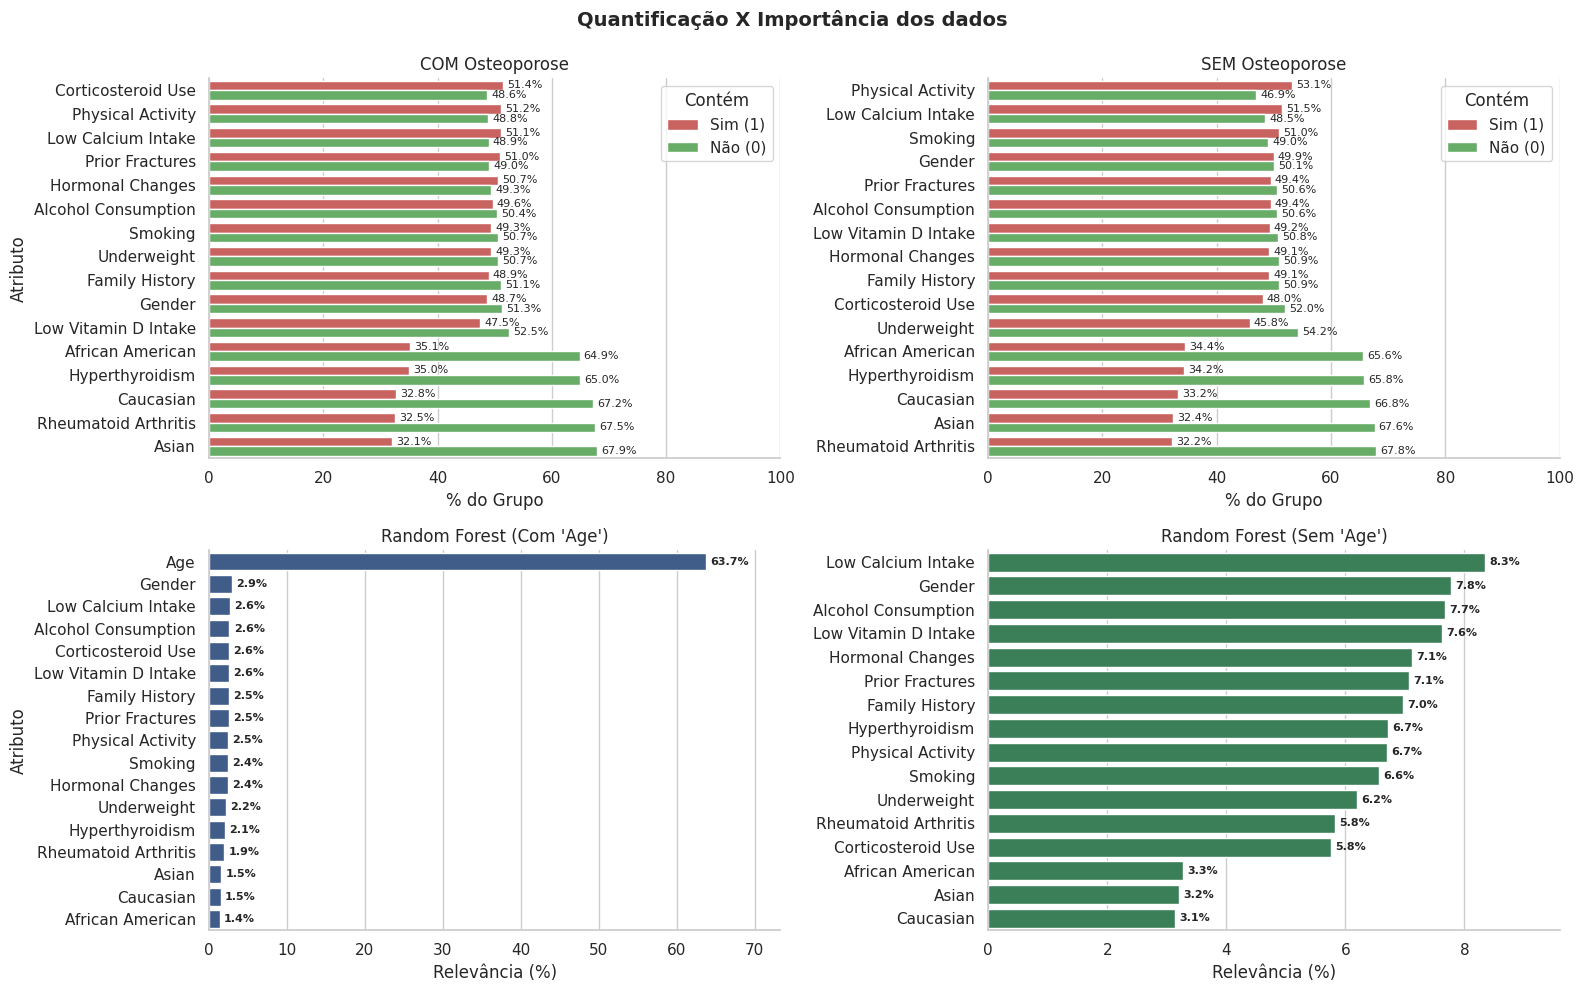

In [223]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

# Estilo e carga
sns.set_theme(style="whitegrid")
df_clean = df.apply(pd.to_numeric, errors="coerce").dropna()
alvo = "Osteoporosis"
y = df_clean[alvo]

# Função para calcular proporção (0 vs 1) em um subconjunto
vars_bin = [c for c in df_clean.columns if c not in [alvo, "Age"] and df_clean[c].nunique() == 2]

def calc_prop(data):
    res = []
    for col in vars_bin:
        f1 = data[col].mean() * 100
        res.append({"Atributo": col, "Sim (1)": f1, "Não (0)": 100 - f1, "Dif": f1 - (100 - f1)})
    return pd.DataFrame(res).sort_values("Dif", ascending=False).melt(id_vars="Atributo", value_vars=["Sim (1)", "Não (0)"], var_name="Contém", value_name="Porcentagem")

# Proporções por grupo
melt_com = calc_prop(df_clean[df_clean[alvo] == 1])
melt_sem = calc_prop(df_clean[df_clean[alvo] == 0])

# Random Forest (Com e Sem Age)
X_com = df_clean.drop(columns=[alvo])
rf_com = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_com, y)
df_rf_com = pd.DataFrame({"Atributo": X_com.columns, "Imp": rf_com.feature_importances_ * 100}).sort_values("Imp", ascending=False)

X_sem = df_clean.drop(columns=[alvo, "Age"], errors="ignore")
rf_sem = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1).fit(X_sem, y)
df_rf_sem = pd.DataFrame({"Atributo": X_sem.columns, "Imp": rf_sem.feature_importances_ * 100}).sort_values("Imp", ascending=False)

# Grid de gráficos
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Fatores em pessoas COM osteoporose
g1 = sns.barplot(data=melt_com, x="Porcentagem", y="Atributo", hue="Contém", palette=["#D9534F", "#5CB85C"], ax=axes[0, 0])
g1.bar_label(g1.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
g1.bar_label(g1.containers[1], fmt="%.1f%%", padding=3, fontsize=8)
axes[0, 0].set(title="COM Osteoporose", xlabel="% do Grupo", xlim=(0, 100))

# 2. Fatores em pessoas SEM osteoporose
g2 = sns.barplot(data=melt_sem, x="Porcentagem", y="Atributo", hue="Contém", palette=["#D9534F", "#5CB85C"], ax=axes[0, 1])
g2.bar_label(g2.containers[0], fmt="%.1f%%", padding=3, fontsize=8)
g2.bar_label(g2.containers[1], fmt="%.1f%%", padding=3, fontsize=8)
axes[0, 1].set(title="SEM Osteoporose", xlabel="% do Grupo", ylabel="", xlim=(0, 100))

# 3. Random Forest (Com Age)
g3 = sns.barplot(data=df_rf_com, x="Imp", y="Atributo", color="#345995", ax=axes[1, 0])
g3.bar_label(g3.containers[0], fmt="%.1f%%", padding=3, fontsize=8, fontweight="bold")
axes[1, 0].set(title="Random Forest (Com 'Age')", xlabel="Relevância (%)", xlim=(0, df_rf_com["Imp"].max() * 1.15))

# 4. Random Forest (Sem Age)
g4 = sns.barplot(data=df_rf_sem, x="Imp", y="Atributo", color="#2E8B57", ax=axes[1, 1])
g4.bar_label(g4.containers[0], fmt="%.1f%%", padding=3, fontsize=8, fontweight="bold")
axes[1, 1].set(title="Random Forest (Sem 'Age')", xlabel="Relevância (%)", ylabel="", xlim=(0, df_rf_sem["Imp"].max() * 1.15))

# Limpeza das bordas
for ax in axes.flat:
    sns.despine(ax=ax)

plt.suptitle("Quantificação X Importância dos dados", fontsize=14, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()

# Divisao de treino e teste


##Separação em treino, teste e validação

In [224]:
# Divisão compartilhada para os modelos que ainda usam as variáveis X_train, X_val e X_test.
# 70% treino, 15% validação e 15% teste, com estratificação da variável-alvo.
X = df.drop(columns=["Osteoporosis"])
y = df["Osteoporosis"]

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    stratify=y_train_val,
    random_state=42
)

print(f"Treino:     {X_train.shape} ({len(X_train) / len(df):.1%})")
print(f"Validação:  {X_val.shape} ({len(X_val) / len(df):.1%})")
print(f"Teste:      {X_test.shape} ({len(X_test) / len(df):.1%})")

Treino:     (1370, 17) (70.0%)
Validação:  (294, 17) (15.0%)
Teste:      (294, 17) (15.0%)


##Verificando divisão

In [225]:
print(f"Dimensão de X_train: {X_train.shape}")
print(f"Dimensão de X_val:   {X_val.shape}")
print(f"Dimensão de X_test:  {X_test.shape}")

print(f"Dimensão de y_train: {y_train.shape}")
print(f"Dimensão de y_val:   {y_val.shape}")
print(f"Dimensão de y_test:  {y_test.shape}")

Dimensão de X_train: (1370, 17)
Dimensão de X_val:   (294, 17)
Dimensão de X_test:  (294, 17)
Dimensão de y_train: (1370,)
Dimensão de y_val:   (294,)
Dimensão de y_test:  (294,)


##Verificando proporçao dos dados de osteoporose entre os dados de treino e teste

In [226]:
# Verificando a proporção das classes nos conjuntos de treino, validação e teste
for nome, alvo in [
    ("treino", y_train),
    ("validação", y_val),
    ("teste", y_test)
]:
    print(f"\nProporção de Osteoporosis nos dados de {nome}:")
    print(alvo.value_counts(normalize=True).sort_index())


Proporção de Osteoporosis nos dados de treino:
Osteoporosis
0    0.5
1    0.5
Name: proportion, dtype: float64

Proporção de Osteoporosis nos dados de validação:
Osteoporosis
0    0.5
1    0.5
Name: proportion, dtype: float64

Proporção de Osteoporosis nos dados de teste:
Osteoporosis
0    0.5
1    0.5
Name: proportion, dtype: float64


#Treinamentos

##Logistic Regression (Regressão Logística) (MARCOS)


###Treinamento

In [227]:
X_train_lr = X_train
X_val_lr = X_val
X_test_lr = X_test

X_train_lr = X_train_lr.drop(columns=['Caucasian'])
X_val_lr = X_val_lr.drop(columns=['Caucasian'])
X_test_lr = X_test_lr.drop(columns=['Caucasian'])
preprocessor = ColumnTransformer(
   transformers=[
         ('age', StandardScaler(), ['Age'])
     ],
    remainder='passthrough'
)

In [228]:
# Modelo e ajuste de hiperparâmetros
logistic_regression = LogisticRegression(solver='liblinear', max_iter=5000, random_state=42)

pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', logistic_regression)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000], 'classifier__penalty': ['l1', 'l2']}
grid_search = GridSearchCV( pipeline, param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid_search.fit(X_train_lr, y_train)

best_model = grid_search.best_estimator_

print('Melhores parâmetros:', grid_search.best_params_)
print(f'Melhor F1 na validação cruzada: {grid_search.best_score_:.4f}')

Melhores parâmetros: {'classifier__C': 0.1, 'classifier__penalty': 'l1'}
Melhor F1 na validação cruzada: 0.8480


###Avaliação (validação + Teste)

In [229]:
# Previsões na Validação
y_pred_lr_val = best_model.predict(X_val_lr)
y_proba_lr_val = best_model.predict_proba(X_val_lr)[:, 1]

# Previsões no Teste
y_pred_lr_test = best_model.predict(X_test_lr)
y_proba_lr_test = best_model.predict_proba(X_test_lr)[:, 1]

resultados_comparativos = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Validação': [
        accuracy_score(y_val, y_pred_lr_val),
        precision_score(y_val, y_pred_lr_val, zero_division=0),
        recall_score(y_val, y_pred_lr_val, zero_division=0),
        f1_score(y_val, y_pred_lr_val, zero_division=0),
        roc_auc_score(y_val, y_proba_lr_val)
    ],
    'Teste': [
        accuracy_score(y_test, y_pred_lr_test),
        precision_score(y_test, y_pred_lr_test, zero_division=0),
        recall_score(y_test, y_pred_lr_test, zero_division=0),
        f1_score(y_test, y_pred_lr_test, zero_division=0),
        roc_auc_score(y_test, y_proba_lr_test)
    ]
})

print("Regressão Logística — Comparativo de Métricas")
display(resultados_comparativos.style.format({'Validação': '{:.4f}', 'Teste': '{:.4f}'}))

Regressão Logística — Comparativo de Métricas


,Métrica,Validação,Teste
0,Accuracy,0.8503,0.8027
1,Precision,0.9120,0.8938
2,Recall,0.7755,0.6871
3,F1-Score,0.8382,0.7769
4,ROC-AUC,0.9127,0.8640


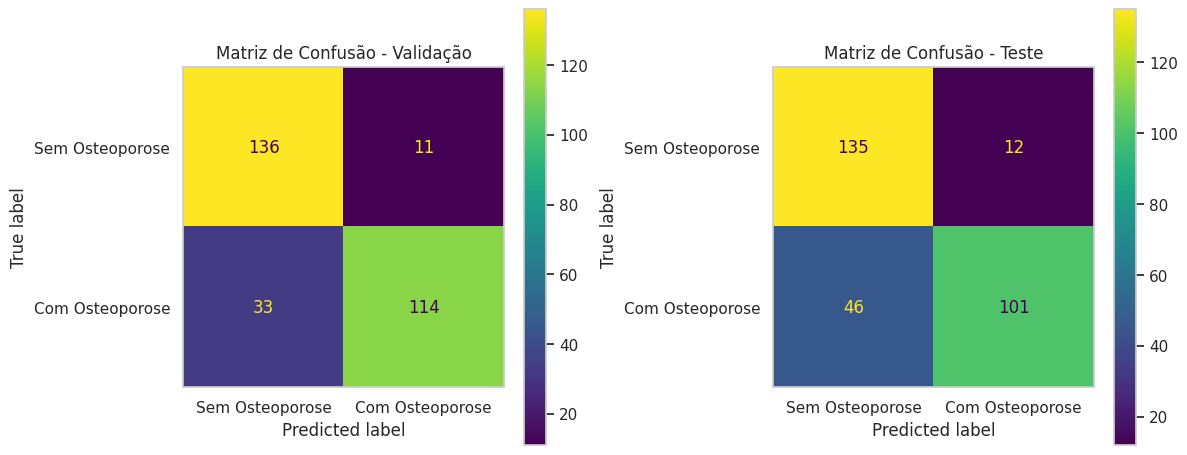

In [230]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Previsões
y_pred_lr_val = best_model.predict(X_val_lr)
y_pred_lr_test = best_model.predict(X_test_lr)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de Validação
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_lr_val,
    display_labels=['Sem Osteoporose', 'Com Osteoporose'],
    ax=axes[0]
)
axes[0].grid(False)
axes[0].set_title('Matriz de Confusão - Validação')

# Matriz de Teste
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr_test,
    display_labels=['Sem Osteoporose', 'Com Osteoporose'],
    ax=axes[1]
)
axes[1].grid(False)
axes[1].set_title('Matriz de Confusão - Teste')

plt.tight_layout()
plt.show()

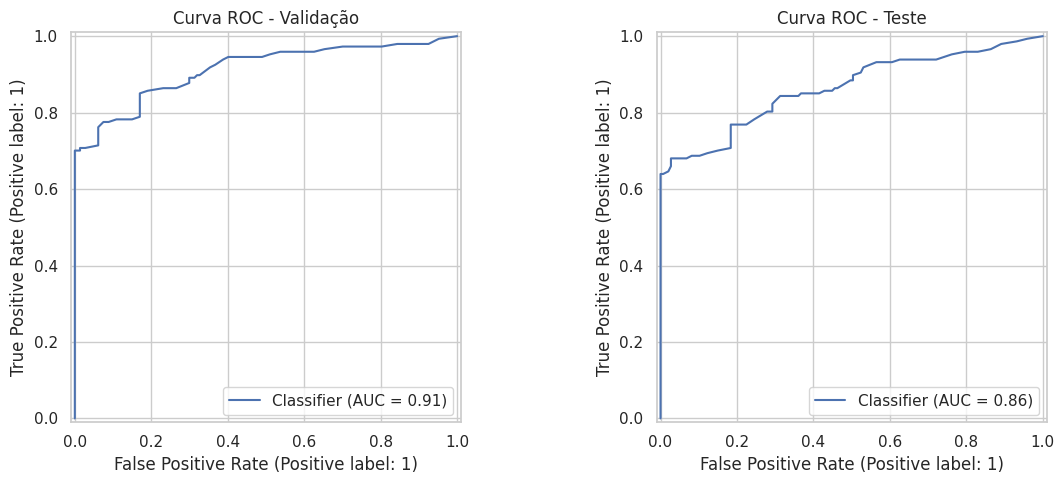

In [231]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Probabilidades
y_proba_lr_val = best_model.predict_proba(X_val_lr)[:, 1]
y_proba_lr_test = best_model.predict_proba(X_test_lr)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Curva ROC de Validação
RocCurveDisplay.from_predictions(
    y_val, y_proba_lr_val,
    ax=axes[0]
)
axes[0].set_title('Curva ROC - Validação')

# Curva ROC de Teste
RocCurveDisplay.from_predictions(
    y_test, y_proba_lr_test,
    ax=axes[1]
)
axes[1].set_title('Curva ROC - Teste')

plt.tight_layout()
plt.show()

###Coeficiantes do Modelo

In [232]:
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = best_model.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({'Feature': feature_names,'Coefficient': coefficients, 'Odds Ratio': np.exp(coefficients)})

coef_df['Abs Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values('Abs Coefficient', ascending=False)

display(coef_df[['Feature', 'Coefficient', 'Odds Ratio']])

,Feature,Coefficient,Odds Ratio
0,age__Age,2.959934,19.296689
10,remainder__Corticosteroid Use,0.073965,1.076769
11,remainder__Prior Fractures,0.061355,1.063277
1,remainder__Gender,0.000000,1.000000
4,remainder__Underweight,0.000000,1.000000
5,remainder__Low Calcium Intake,0.000000,1.000000
2,remainder__Hormonal Changes,0.000000,1.000000
3,remainder__Family History,0.000000,1.000000
7,remainder__Physical Activity,0.000000,1.000000
6,remainder__Low Vitamin D Intake,0.000000,1.000000


In [233]:
feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = best_model.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Odds Ratio': np.exp(coefficients)
})

# Remover prefixos técnicos criados pelo ColumnTransformer
coef_df['Feature'] = (
    coef_df['Feature']
    .str.replace('age__', '', regex=False)
    .str.replace('remainder__', '', regex=False)
)

# Nomes mais claros para apresentação
nomes_variaveis = {
    'Age': 'Idade (padronizada)',
    'Gender': 'Sexo feminino',
    'Hormonal Changes': 'Pós-menopausa',
    'Family History': 'Histórico familiar',
    'Underweight': 'Abaixo do peso',
    'Low Calcium Intake': 'Baixa ingestão de cálcio',
    'Low Vitamin D Intake': 'Vitamina D insuficiente',
    'Physical Activity': 'Atividade física',
    'Smoking': 'Tabagismo',
    'Alcohol Consumption': 'Consumo de álcool',
    'Corticosteroid Use': 'Uso de corticosteroides',
    'Prior Fractures': 'Fraturas anteriores',
    'African': 'Etnia africana',
    'Asian': 'Etnia asiática',
    'Caucasian' :'Etnia Caucasiana',
    'Rheumatoid Arthritis': 'Artrite reumatoide',
    'Hyperthyroidism': 'Hipertireoidismo'
}

coef_df['Feature'] = coef_df['Feature'].replace(nomes_variaveis)

coef_df['Abs Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values('Abs Coefficient', ascending=False)

display(coef_df[['Feature', 'Coefficient', 'Odds Ratio']])


,Feature,Coefficient,Odds Ratio
0,Idade (padronizada),2.959934,19.296689
10,Uso de corticosteroides,0.073965,1.076769
11,Fraturas anteriores,0.061355,1.063277
1,Sexo feminino,0.000000,1.000000
4,Abaixo do peso,0.000000,1.000000
5,Baixa ingestão de cálcio,0.000000,1.000000
2,Pós-menopausa,0.000000,1.000000
3,Histórico familiar,0.000000,1.000000
7,Atividade física,0.000000,1.000000
6,Vitamina D insuficiente,0.000000,1.000000


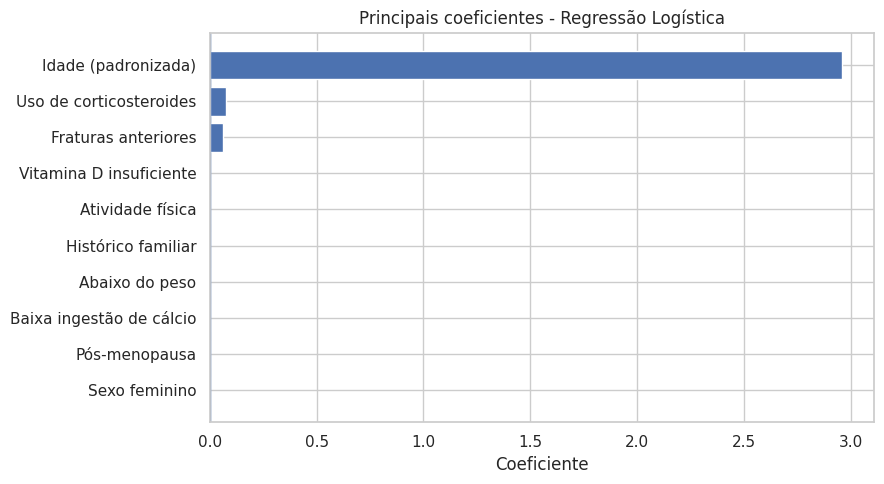

In [234]:
plot_df = coef_df.head(10).sort_values('Coefficient')

plt.figure(figsize=(9, 5))
plt.barh(plot_df['Feature'], plot_df['Coefficient'])
plt.axvline(0, linewidth=1)
plt.xlabel('Coeficiente')
plt.title('Principais coeficientes - Regressão Logística')
plt.tight_layout()
plt.show()

##Random Forest (Florestas Aleatórias)(Lucas)

###Treinamento

In [235]:
X_train_rf= X_train
X_val_rf= X_val
X_test_rf = X_test
y_train_rf = y_train
y_val_rf = y_val
y_test_rf = y_test

In [236]:
# Validação cruzada é feita somente dentro do conjunto de treino.
cv_rf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

parametros_rf = {
    "n_estimators": [100, 200, 300, 500, 700],
    "max_depth": [None, 8, 12, 16, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7, 1.0],
    "class_weight": [None, "balanced"]
}

modelo_base_rf = RandomForestClassifier(random_state=42, n_jobs=1)

busca_rf = RandomizedSearchCV(
    estimator=modelo_base_rf,
    param_distributions=parametros_rf,
    n_iter=60,
    scoring="accuracy",
    cv=cv_rf,
    random_state=42,
    n_jobs=-1,
    refit=True,
    verbose=1
)

busca_rf.fit(X_train_rf, y_train_rf)
modelo_rf = busca_rf.best_estimator_

print("Melhores parâmetros:")
print(busca_rf.best_params_)
print(f"\nAcurácia média na validação cruzada: {busca_rf.best_score_:.4f}")

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Melhores parâmetros:
{'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 8, 'class_weight': 'balanced'}

Acurácia média na validação cruzada: 0.9197


###Avaliação (validação + Teste)

In [237]:
# Métricas de validação cruzada no conjunto de treino do Random Forest.
cv_rf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

resultados_cv_rf = cross_validate(
    modelo_rf,
    X_train_rf,
    y_train_rf,
    cv=cv_rf,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Random Forest — validação cruzada (5 folds)")
print(f"Accuracy média:  {resultados_cv_rf['test_accuracy'].mean():.4f}")
print(f"Precision média: {resultados_cv_rf['test_precision'].mean():.4f}")
print(f"Recall médio:    {resultados_cv_rf['test_recall'].mean():.4f}")
print(f"F1-Score médio:  {resultados_cv_rf['test_f1'].mean():.4f}")
print(f"ROC-AUC médio:   {resultados_cv_rf['test_roc_auc'].mean():.4f}")

Random Forest — validação cruzada (5 folds)
Accuracy média:  0.9197
Precision média: 0.9930
Recall médio:    0.8453
F1-Score médio:  0.9130
ROC-AUC médio:   0.9324


In [238]:
# Cálculo das métricas de teste
y_pred_rf_test = modelo_rf.predict(X_test_rf)
y_proba_rf_test = modelo_rf.predict_proba(X_test_rf)[:, 1]

metricas = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

# Se houver dados de validação, calcula e exibe ambos lado a lado
if X_val_rf is not None:
    y_pred_rf_val = modelo_rf.predict(X_val_rf)
    y_proba_rf_val = modelo_rf.predict_proba(X_val_rf)[:, 1]

    resultados_comparativos = pd.DataFrame({
        "Métrica": metricas,
        "Validação": [
            accuracy_score(y_val_rf, y_pred_rf_val),
            precision_score(y_val_rf, y_pred_rf_val, zero_division=0),
            recall_score(y_val_rf, y_pred_rf_val, zero_division=0),
            f1_score(y_val_rf, y_pred_rf_val, zero_division=0),
            roc_auc_score(y_val_rf, y_proba_rf_val)
        ],
        "Teste": [
            accuracy_score(y_test_rf, y_pred_rf_test),
            precision_score(y_test_rf, y_pred_rf_test, zero_division=0),
            recall_score(y_test_rf, y_pred_rf_test, zero_division=0),
            f1_score(y_test_rf, y_pred_rf_test, zero_division=0),
            roc_auc_score(y_test_rf, y_proba_rf_test)
        ]
    })
else:
    resultados_comparativos = pd.DataFrame({
        "Métrica": metricas,
        "Teste": [
            accuracy_score(y_test_rf, y_pred_rf_test),
            precision_score(y_test_rf, y_pred_rf_test, zero_division=0),
            recall_score(y_test_rf, y_pred_rf_test, zero_division=0),
            f1_score(y_test_rf, y_pred_rf_test, zero_division=0),
            roc_auc_score(y_test_rf, y_proba_rf_test)
        ]
    })

print("Random Forest — Comparativo de Métricas")
display(resultados_comparativos.style.format({col: "{:.4f}" for col in resultados_comparativos.columns if col != "Métrica"}))

Random Forest — Comparativo de Métricas


,Métrica,Validação,Teste
0,Accuracy,0.9116,0.8707
1,Precision,1.0000,1.0000
2,Recall,0.8231,0.7415
3,F1-Score,0.9030,0.8516
4,ROC-AUC,0.9232,0.8788


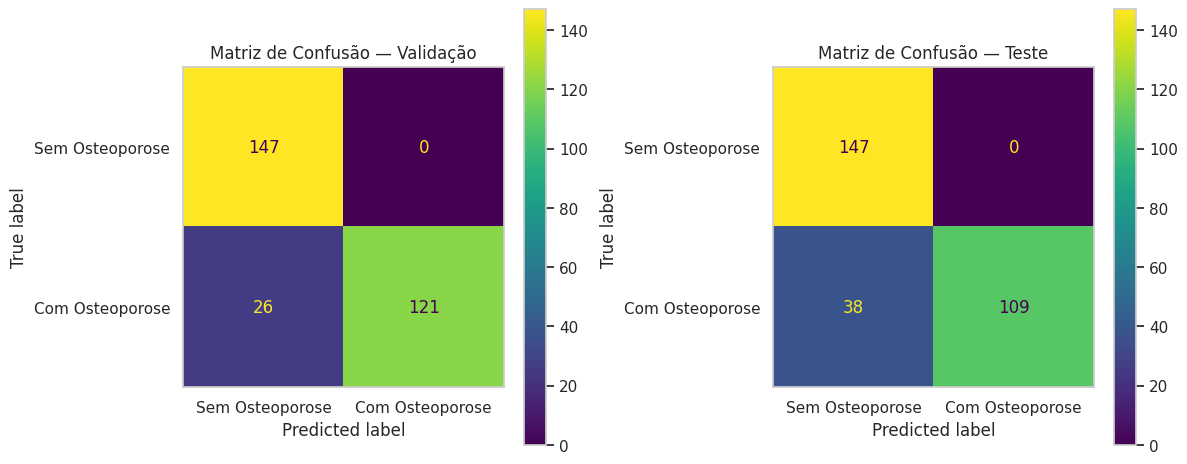

In [239]:
# Garante a previsão do teste
y_pred_rf_test = modelo_rf.predict(X_test_rf)

if X_val_rf is not None:
    y_pred_rf_val = modelo_rf.predict(X_val_rf)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Matriz de Validação
    ConfusionMatrixDisplay.from_predictions(
        y_val_rf, y_pred_rf_val,
        display_labels=["Sem Osteoporose", "Com Osteoporose"],
        ax=axes[0]
    )
    axes[0].set_title("Matriz de Confusão — Validação")
    axes[0].grid(False)
    # Matriz de Teste
    ConfusionMatrixDisplay.from_predictions(
        y_test_rf, y_pred_rf_test,
        display_labels=["Sem Osteoporose", "Com Osteoporose"],
        ax=axes[1]
    )
    axes[1].grid(False)
    axes[1].set_title("Matriz de Confusão — Teste")

    plt.tight_layout()
    plt.show()
else:
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test_rf, y_pred_rf_test,
        display_labels=["Sem Osteoporose", "Com Osteoporose"],
        ax=ax
    )
    ax.set_title("Matriz de Confusão — Teste")
    plt.tight_layout()
    plt.show()

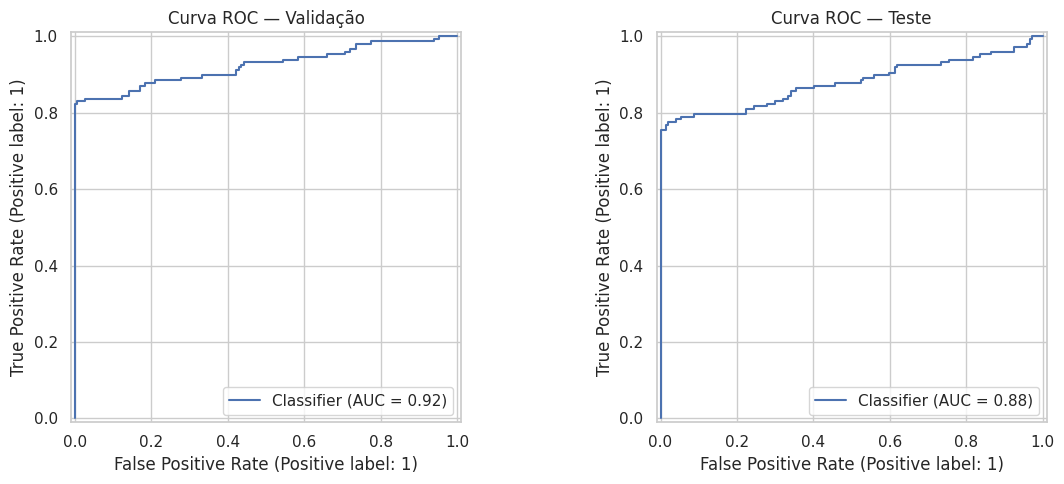

In [240]:
# Garante as probabilidades do teste
y_proba_rf_test = modelo_rf.predict_proba(X_test_rf)[:, 1]

if X_val_rf is not None:
    y_proba_rf_val = modelo_rf.predict_proba(X_val_rf)[:, 1]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Curva ROC de Validação
    RocCurveDisplay.from_predictions(
        y_val_rf, y_proba_rf_val,
        ax=axes[0]
    )
    axes[0].set_title("Curva ROC — Validação")

    # Curva ROC de Teste
    RocCurveDisplay.from_predictions(
        y_test_rf, y_proba_rf_test,
        ax=axes[1]
    )
    axes[1].set_title("Curva ROC — Teste")

    plt.tight_layout()
    plt.show()
else:
    fig, ax = plt.subplots(figsize=(6, 5))
    RocCurveDisplay.from_predictions(
        y_test_rf, y_proba_rf_test,
        ax=ax
    )
    ax.set_title("Curva ROC — Teste")
    plt.tight_layout()
    plt.show()

###Explicabilidade do Random Forest com SHAP.

SHAP — importância global das variáveis


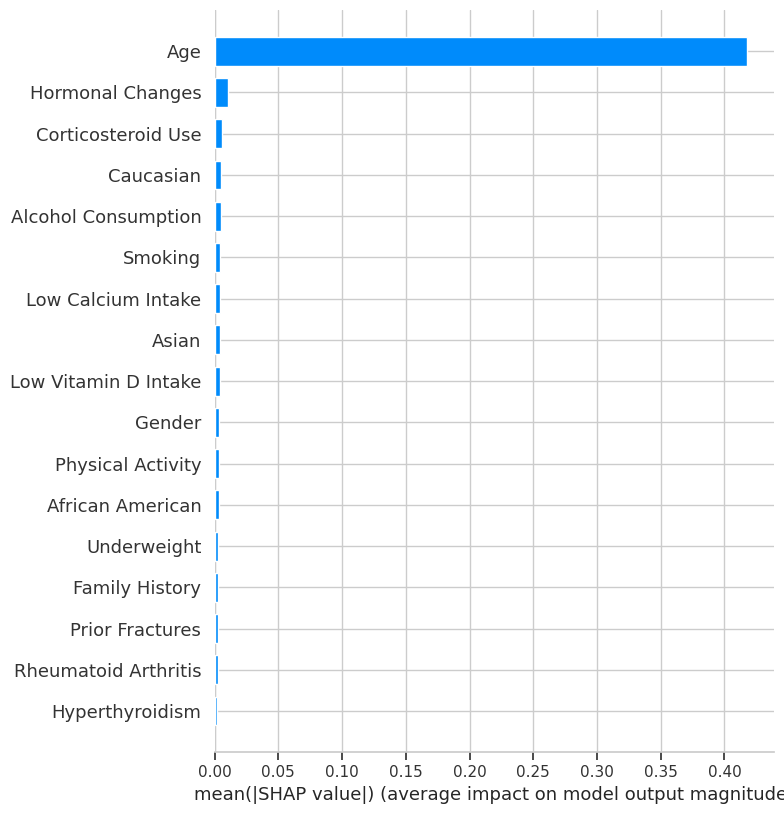

SHAP — impacto das variáveis nas previsões


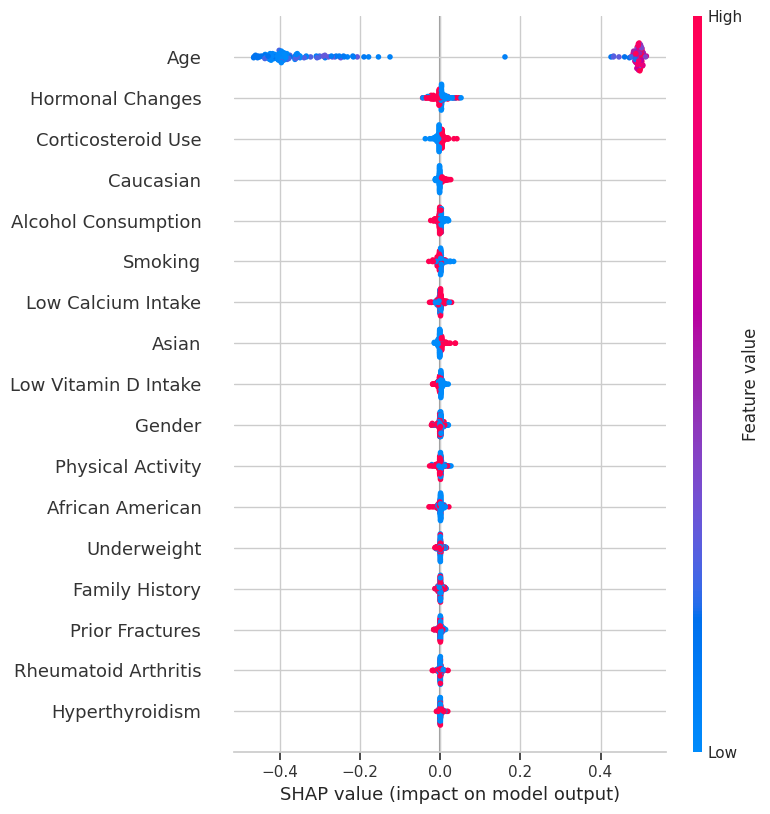

In [241]:
# Usa uma amostra do conjunto de treino apenas para explicar as previsões, não para medir desempenho.
X_shap = X_train_rf.sample(
    n=min(200, len(X_train_rf)),
    random_state=42
)

explainer_rf = shap.TreeExplainer(modelo_rf)
shap_values_rf = explainer_rf(X_shap)

# Compatibilidade com versões do SHAP que retornam valores separados por classe.
valores_shap_rf = shap_values_rf.values
if valores_shap_rf.ndim == 3:
    # Para classificação binária, explica a classe positiva (Com Osteoporose).
    valores_shap_rf = valores_shap_rf[:, :, 1]

print("SHAP — importância global das variáveis")
shap.summary_plot(
    valores_shap_rf,
    X_shap,
    plot_type="bar",
    show=True
)

print("SHAP — impacto das variáveis nas previsões")
shap.summary_plot(
    valores_shap_rf,
    X_shap,
    show=True
)

##Gradient Boosting (XGBoost) (MARIA)

###Treinamento

In [242]:
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=1
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
}
grid_search_xgb = GridSearchCV(XGBClassifier(eval_metric="logloss", random_state=42), param_grid_xgb, scoring='f1', cv=3, n_jobs=-1)

#grid_search_xgb = GridSearchCV(xgb, param_grid_xgb, scoring='f1', cv=cv, n_jobs=-1)
grid_search_xgb.fit(X_train, y_train)

print('Melhores parâmetros:', grid_search_xgb.best_params_)
print(f'Melhor F1 na validação cruzada: {grid_search_xgb.best_score_:.4f}')

Melhores parâmetros: {'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 200, 'subsample': 1.0}
Melhor F1 na validação cruzada: 0.9154


In [243]:
# Verificação de possível overfitting
best_xgb = grid_search_xgb.best_estimator_

y_pred_xgb_train = best_xgb.predict(X_train)
y_pred_xgb_val = best_xgb.predict(X_val)

print('Desempenho no conjunto de treinamento:')
print(f'Accuracy: {accuracy_score(y_train, y_pred_xgb_train):.4f}')
print(f'F1-Score: {f1_score(y_train, y_pred_xgb_train, zero_division=0):.4f}')

print('\nDesempenho no conjunto de validação:')
print(f'Accuracy: {accuracy_score(y_val, y_pred_xgb_val):.4f}')
print(f'F1-Score: {f1_score(y_val, y_pred_xgb_val, zero_division=0):.4f}')

Desempenho no conjunto de treinamento:
Accuracy: 0.9299
F1-Score: 0.9246

Desempenho no conjunto de validação:
Accuracy: 0.9082
F1-Score: 0.8996


###Avaliação (validação + Teste)

In [244]:
print('Relatório de Classificação - XGBoost (Validação)')
print(
    classification_report(
        y_val,
        y_pred_xgb_val,
        target_names=['Sem Osteoporose', 'Com Osteoporose'],
        zero_division=0
    )
)

Relatório de Classificação - XGBoost (Validação)
                 precision    recall  f1-score   support

Sem Osteoporose       0.85      0.99      0.92       147
Com Osteoporose       0.99      0.82      0.90       147

       accuracy                           0.91       294
      macro avg       0.92      0.91      0.91       294
   weighted avg       0.92      0.91      0.91       294



In [245]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Previsões na Validação
y_pred_xgb_val = best_xgb.predict(X_val)
y_proba_xgb_val = best_xgb.predict_proba(X_val)[:, 1]

# Previsões no Teste
y_pred_xgb_test = best_xgb.predict(X_test)
y_proba_xgb_test = best_xgb.predict_proba(X_test)[:, 1]

resultados_comparativos = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Validação': [
        accuracy_score(y_val, y_pred_xgb_val),
        precision_score(y_val, y_pred_xgb_val, zero_division=0),
        recall_score(y_val, y_pred_xgb_val, zero_division=0),
        f1_score(y_val, y_pred_xgb_val, zero_division=0),
        roc_auc_score(y_val, y_proba_xgb_val)
    ],
    'Teste': [
        accuracy_score(y_test, y_pred_xgb_test),
        precision_score(y_test, y_pred_xgb_test, zero_division=0),
        recall_score(y_test, y_pred_xgb_test, zero_division=0),
        f1_score(y_test, y_pred_xgb_test, zero_division=0),
        roc_auc_score(y_test, y_proba_xgb_test)
    ]
})

print("XGBoost — Comparativo de Métricas")
display(resultados_comparativos.style.format({'Validação': '{:.4f}', 'Teste': '{:.4f}'}))

XGBoost — Comparativo de Métricas


,Métrica,Validação,Teste
0,Accuracy,0.9082,0.8673
1,Precision,0.9918,0.9909
2,Recall,0.8231,0.7415
3,F1-Score,0.8996,0.8482
4,ROC-AUC,0.9246,0.8798


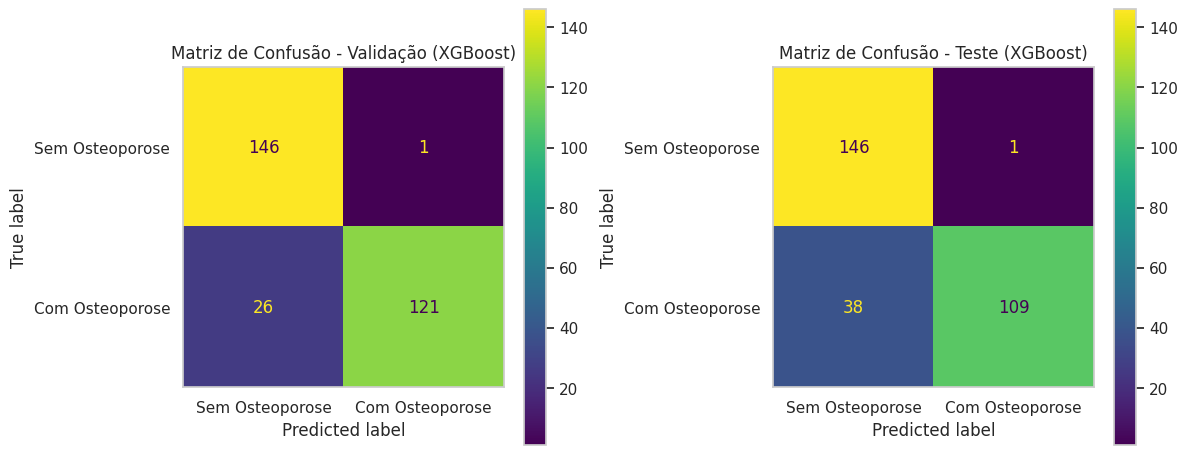

In [246]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Previsões
y_pred_xgb_val = best_xgb.predict(X_val)
y_pred_xgb_test = best_xgb.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz de Validação
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred_xgb_val,
    display_labels=['Sem Osteoporose', 'Com Osteoporose'],
    ax=axes[0]
)
axes[0].grid(False)
axes[0].set_title('Matriz de Confusão - Validação (XGBoost)')

# Matriz de Teste
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_xgb_test,
    display_labels=['Sem Osteoporose', 'Com Osteoporose'],
    ax=axes[1]
)
axes[1].grid(False)
axes[1].set_title('Matriz de Confusão - Teste (XGBoost)')

plt.tight_layout()
plt.show()

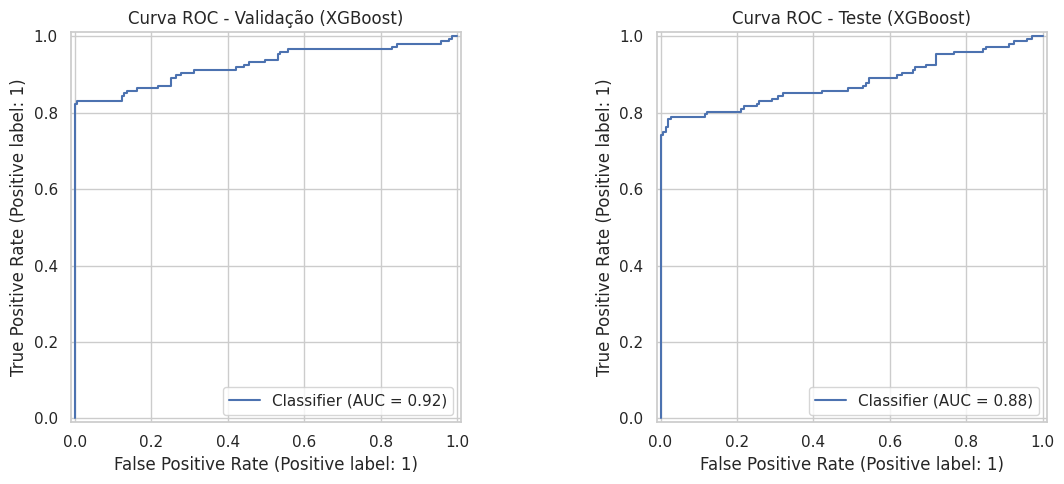

In [247]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

# Probabilidades
y_proba_xgb_val = best_xgb.predict_proba(X_val)[:, 1]
y_proba_xgb_test = best_xgb.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Curva ROC de Validação
RocCurveDisplay.from_predictions(
    y_val, y_proba_xgb_val,
    ax=axes[0]
)
axes[0].set_title('Curva ROC - Validação (XGBoost)')

# Curva ROC de Teste
RocCurveDisplay.from_predictions(
    y_test, y_proba_xgb_test,
    ax=axes[1]
)
axes[1].set_title('Curva ROC - Teste (XGBoost)')

plt.tight_layout()
plt.show()

###Importancia de Permutação


In [248]:
df_importancia_xgb = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance (gain)': best_xgb.feature_importances_
})

perm_xgb = permutation_importance(best_xgb, X_val, y_val, scoring='f1', n_repeats=20, random_state=42, n_jobs=-1)
df_importancia_xgb['Importance (permutation)'] = perm_xgb.importances_mean

df_importancia_xgb = df_importancia_xgb.sort_values('Importance (permutation)', ascending=False)
display(df_importancia_xgb.round(4))

,Feature,Importance (gain),Importance (permutation)
0,Age,0.6316,0.4473
5,Low Calcium Intake,0.0226,0.0015
4,Underweight,0.0224,0.0010
12,African American,0.0280,0.0007
7,Physical Activity,0.0236,0.0000
8,Smoking,0.0268,0.0000
15,Hyperthyroidism,0.0160,0.0000
11,Prior Fractures,0.0324,0.0000
2,Hormonal Changes,0.0130,0.0000
16,Rheumatoid Arthritis,0.0257,0.0000


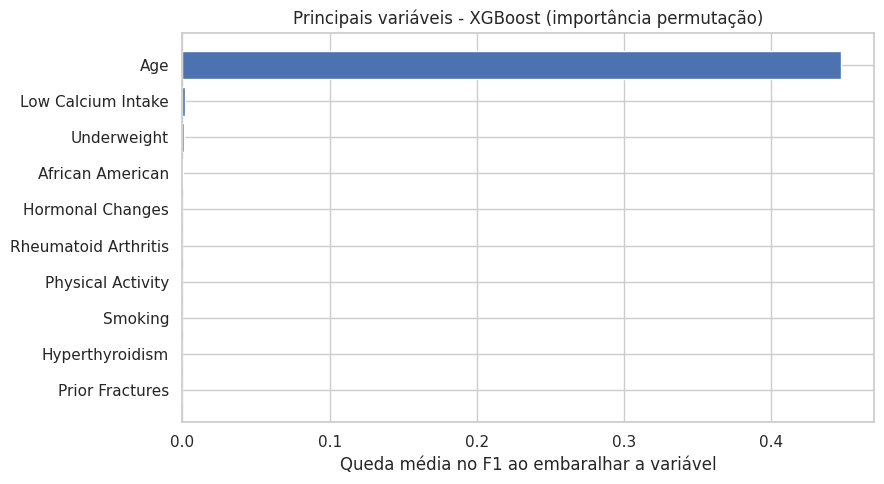

In [249]:
plot_df_xgb = df_importancia_xgb.head(10).sort_values('Importance (permutation)')

plt.figure(figsize=(9, 5))
plt.barh(plot_df_xgb['Feature'], plot_df_xgb['Importance (permutation)'])
plt.xlabel('Queda média no F1 ao embaralhar a variável')
plt.title('Principais variáveis - XGBoost (importância permutação)')
plt.tight_layout()
plt.show()

#Comparando Modelos

## Regressão Logistica X Random Forest X Gradient Boosting

,Modelo,Etapa,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Regressão Logística,Validação,0.8503,0.9120,0.7755,0.8382,0.9127
1,Regressão Logística,Teste,0.8027,0.8938,0.6871,0.7769,0.8640
2,Regressão Logística,Variação (Val - Test),0.0476,0.0182,0.0884,0.0613,0.0487
3,Random Forest,Validação,0.9116,1.0000,0.8231,0.9030,0.9232
4,Random Forest,Teste,0.8707,1.0000,0.7415,0.8516,0.8788
5,Random Forest,Variação (Val - Test),0.0408,0.0000,0.0816,0.0514,0.0444
6,XGBoost,Validação,0.9082,0.9918,0.8231,0.8996,0.9246
7,XGBoost,Teste,0.8673,0.9909,0.7415,0.8482,0.8798
8,XGBoost,Variação (Val - Test),0.0408,0.0009,0.0816,0.0514,0.0448


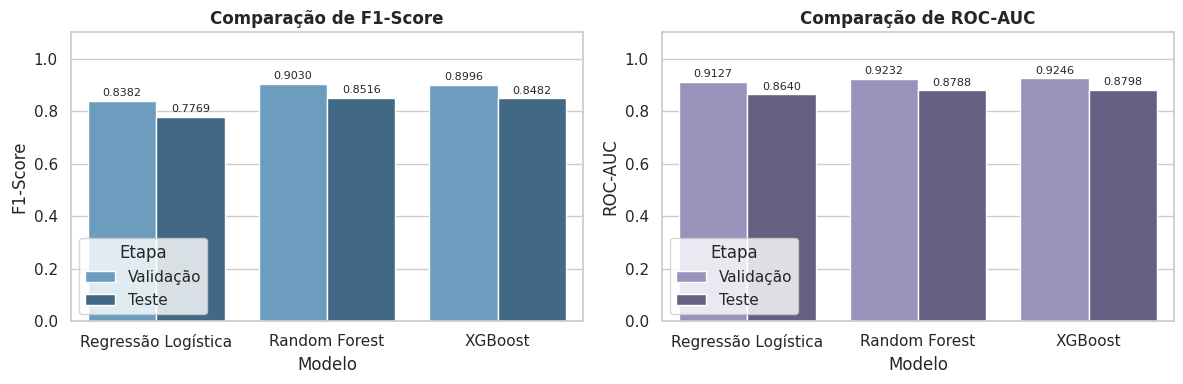

In [250]:
modelos_dados = {}

if "y_pred_lr_val" in globals() and "y_pred_lr_test" in globals():
    modelos_dados["Regressão Logística"] = {
        "val": (y_val, y_pred_lr_val, y_proba_lr_val),
        "test": (y_test, y_pred_lr_test, y_proba_lr_test)
    }

if globals().get("y_pred_rf_val") is not None and "y_pred_rf_test" in globals():
    modelos_dados["Random Forest"] = {
        "val": (y_val_rf, y_pred_rf_val, y_proba_rf_val),
        "test": (y_test_rf, y_pred_rf_test, y_proba_rf_test)
    }

if "y_pred_xgb_val" in globals() and "y_pred_xgb_test" in globals():
    modelos_dados["XGBoost"] = {
        "val": (y_val, y_pred_xgb_val, y_proba_xgb_val),
        "test": (y_test, y_pred_xgb_test, y_proba_xgb_test)
    }

if modelos_dados:
    linhas = []
    cols = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]

    for nome, dados in modelos_dados.items():
        y_v, y_pred_v, y_prob_v = dados["val"]
        y_t, y_pred_t, y_prob_t = dados["test"]

        metrics_v = [accuracy_score(y_v, y_pred_v), precision_score(y_v, y_pred_v, zero_division=0),
                     recall_score(y_v, y_pred_v, zero_division=0), f1_score(y_v, y_pred_v, zero_division=0),
                     roc_auc_score(y_v, y_prob_v)]

        metrics_t = [accuracy_score(y_t, y_pred_t), precision_score(y_t, y_pred_t, zero_division=0),
                     recall_score(y_t, y_pred_t, zero_division=0), f1_score(y_t, y_pred_t, zero_division=0),
                     roc_auc_score(y_t, y_prob_t)]

        linhas.append({"Modelo": nome, "Etapa": "Validação", **dict(zip(cols, metrics_v))})
        linhas.append({"Modelo": nome, "Etapa": "Teste", **dict(zip(cols, metrics_t))})
        linhas.append({"Modelo": nome, "Etapa": "Variação (Val - Test)", **dict(zip(cols, [v - t for v, t in zip(metrics_v, metrics_t)]))})

    df_comp = pd.DataFrame(linhas)

    display(df_comp.style.apply(
        lambda r: ["background-color: #fff3cd; color: #856404; font-weight: bold"] * len(r) if r["Etapa"] == "Variação (Val - Test)" else [""] * len(r), axis=1
    ).format({col: "{:.4f}" for col in cols}))

    df_plot = df_comp[df_comp["Etapa"].isin(["Validação", "Teste"])]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for idx, (metrica, paleta) in enumerate([("F1-Score", "Blues_d"), ("ROC-AUC", "Purples_d")]):
        sns.barplot(data=df_plot, x="Modelo", y=metrica, hue="Etapa", palette=paleta, ax=axes[idx])
        axes[idx].set_title(f"Comparação de {metrica}", fontweight="bold")
        axes[idx].set_ylim(0, 1.1)

        for p in axes[idx].patches:
            if p.get_height() > 0:
                axes[idx].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                                   ha='center', va='bottom', fontsize=8, xytext=(0, 2), textcoords='offset points')

    plt.tight_layout()
    plt.show()
else:
    print("Nenhum modelo disponível para comparação.")

##Melhor Modelo

🏆 MELHOR MODELO: RANDOM FOREST
--------------------------------------------------
• Validação -> F1-Score: 0.9030 | ROC-AUC: 0.9232
• Teste     -> F1-Score: 0.8516 | ROC-AUC: 0.8788
--------------------------------------------------


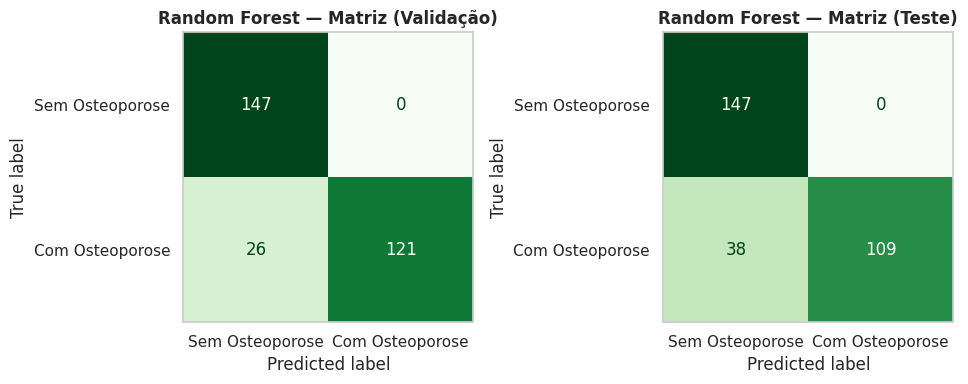

In [251]:
if "df_comp" in globals() and not df_comp.empty:
    df_teste = df_comp[df_comp["Etapa"] == "Teste"].sort_values(by="F1-Score", ascending=False)
    nome_melhor = df_teste.iloc[0]["Modelo"]

    m_val = df_comp[(df_comp["Modelo"] == nome_melhor) & (df_comp["Etapa"] == "Validação")].iloc[0]
    m_test = df_comp[(df_comp["Modelo"] == nome_melhor) & (df_comp["Etapa"] == "Teste")].iloc[0]

    print(f"🏆 MELHOR MODELO: {nome_melhor.upper()}")
    print("-" * 50)
    print(f"• Validação -> F1-Score: {m_val['F1-Score']:.4f} | ROC-AUC: {m_val['ROC-AUC']:.4f}")
    print(f"• Teste     -> F1-Score: {m_test['F1-Score']:.4f} | ROC-AUC: {m_test['ROC-AUC']:.4f}")
    print("-" * 50)

    dados_m = modelos_dados[nome_melhor]
    labels = ["Sem Osteoporose", "Com Osteoporose"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, (y_real, y_p, titulo) in zip(axes, [(dados_m["val"][0], dados_m["val"][1], "Validação"),
                                                (dados_m["test"][0], dados_m["test"][1], "Teste")]):
        cm = confusion_matrix(y_real, y_p)
        ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels).plot(
            ax=ax, cmap=cores.get(nome_melhor, "Blues"), colorbar=False
        )
        ax.set_title(f"{nome_melhor} — Matriz ({titulo})", fontweight="bold")
        ax.grid(False)

    plt.tight_layout()
    plt.show()
else:
    print("Execute o código de comparação de modelos primeiro.")